# Optimizer comparison over seeds

In [1]:
import os, json, time, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans"})

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "ablation_results"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| PyTorch", torch.__version__)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")
    plt.show()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

Device: cpu | PyTorch 2.11.0+cpu


## Configuration


In [ ]:
TARGET = "Pregnancy_Outcome"

RUN_DFSAMRFO       = True
OPT_POP            = 10
OPT_ITERS          = 20        # iterations (T)
OPT_EPOCHS         = 10        # epochs per candidate
OPT_TRAIN_FRACTION = 0.5       # stratified fraction of the training subset
OPT_PATIENCE       = 4         # early stopping

FINAL_EPOCHS       = 50
RES_ALPHA          = 0.10      # residual scaling coefficient
TAU                = 0.5       # decision threshold
EPS_CLIP           = 1e-7      # probability clipping

#  optimized configuration
DEFAULT_HPARAMS = dict(lr=0.0008, emb_dim=64, n_blocks=4, n_heads=4,
                      fm_hidden=256, dropout=0.30, batch_size=128, l2=1e-4)

# SHAP settings
SHAP_N_EXPLAIN    = 500        # test records
SHAP_N_BACKGROUND = 100        # background records

## Data upload

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "pregnancy_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.lower().endswith(".csv") else pd.read_excel(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)

# drop identifier-like columns
id_like = [c for c in df.columns if c.lower() in ("id", "patient_id", "patientid", "record_id", "unnamed: 0")]
df = df.drop(columns=id_like)
print("Dropped identifier columns:", id_like)

# encode the target as 1 = Pregnant, 0 = Not Pregnant
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    t = df[TARGET].astype(str).str.strip().str.lower()
    df[TARGET] = t.map(lambda v: 0 if ("not" in v or v in ("0", "no", "negative")) else 1).astype(int)
CLASS_NAMES = ["Not Pregnant", "Pregnant"]
print(df[TARGET].value_counts().rename(index={0: "Not Pregnant (0)", 1: "Pregnant (1)"}))

Saving Pregnancy_Prediction.csv to Pregnancy_Prediction.csv
Shape: (50000, 41)
Dropped identifier columns: []
Pregnancy_Outcome
Pregnant (1)        34404
Not Pregnant (0)    15596
Name: count, dtype: int64


## Stratified 70:15:15 partitioning

In [ ]:
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET].values.astype(int)

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_tbl = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Records": [len(y_train), len(y_val), len(y_test)],
    "Not Pregnant (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Pregnant (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]})
print(split_tbl.to_string(index=False))

    Subset  Records  Not Pregnant (0)  Pregnant (1)
  Training    35000             10917         24083
Validation     7500              2339          5161
   Testing     7500              2340          5160


## Leakage-free preprocessing


In [ ]:
print("Missing values in the complete dataset:", int(df.isna().sum().sum()))
print("Exact duplicate records:", int(df.duplicated().sum()))

MULTI_CAT_HINTS = ["exercise", "stress", "diet"]

num_cols, bin_cols, cat_cols = [], [], []
for c in X_train_raw.columns:
    s = X_train_raw[c]
    nun = s.dropna().nunique()
    if not pd.api.types.is_numeric_dtype(s):
        (bin_cols if nun <= 2 else cat_cols).append(c)
    elif any(h in c.lower() for h in MULTI_CAT_HINTS) and nun <= 10:
        cat_cols.append(c)
    elif nun <= 2:
        bin_cols.append(c)
    else:
        num_cols.append(c)
print(f"Continuous: {len(num_cols)} | Binary: {len(bin_cols)} | Multi-category: {len(cat_cols)}")
print("Multi-category columns:", cat_cols)

class TabularPreprocessor:
    def fit(self, X):
        self.medians = X[num_cols].median()
        self.bin_maps, self.bin_modes = {}, {}
        for c in bin_cols:
            vals = sorted(X[c].dropna().unique(), key=lambda v: str(v))
            pos = [v for v in vals if str(v).strip().lower() in ("1", "1.0", "yes", "true", "y", "present", "positive")]
            if pos:
                self.bin_maps[c] = {v: (1 if v in pos else 0) for v in vals}
            else:
                self.bin_maps[c] = {v: i for i, v in enumerate(vals)}
            self.bin_modes[c] = X[c].mode().iloc[0]
        self.cat_modes = {c: X[c].mode().iloc[0] for c in cat_cols}
        self.cat_vocab = {c: {v: i for i, v in enumerate(sorted(X[c].dropna().unique(), key=lambda v: str(v)))}
                          for c in cat_cols}
        Xn = X[num_cols].fillna(self.medians).astype(float)
        self.mu, self.sigma = Xn.mean(), Xn.std(ddof=0)
        return self

    def raw_imputed(self, X):
        out = pd.DataFrame(index=X.index)
        for c in num_cols: out[c] = X[c].fillna(self.medians[c]).astype(float)
        for c in bin_cols: out[c] = X[c].fillna(self.bin_modes[c]).map(self.bin_maps[c]).fillna(0).astype(float)
        for c in cat_cols:
            out[c] = X[c].fillna(self.cat_modes[c]).map(self.cat_vocab[c]).fillna(len(self.cat_vocab[c])).astype(float)
        return out

    def transform(self, X):
        R = self.raw_imputed(X)
        x_num = ((R[num_cols] - self.mu) / (self.sigma + 1e-8)).values if num_cols else np.zeros((len(X), 0))
        x_bin = R[bin_cols].values if bin_cols else np.zeros((len(X), 0))
        x_cont = np.hstack([x_num, x_bin]).astype(np.float32)
        x_cat = R[cat_cols].values.astype(np.int64) if cat_cols else np.zeros((len(X), 0), np.int64)
        return x_cont, x_cat

prep = TabularPreprocessor().fit(X_train_raw)
Xc_tr, Xk_tr = prep.transform(X_train_raw)
Xc_va, Xk_va = prep.transform(X_val_raw)
Xc_te, Xk_te = prep.transform(X_test_raw)

CAT_CARDINALITIES = [len(prep.cat_vocab[c]) + 1 for c in cat_cols]
print("Continuous tensor:", Xc_tr.shape, "| Categorical tensor:", Xk_tr.shape)

# class weights: w_c = N / (K * N_c)
N_tr, K = len(y_train), 2
CLASS_W = torch.tensor([N_tr / (K * (y_train == c).sum()) for c in (0, 1)], dtype=torch.float32)
print("Class weights  w0 = %.4f, w1 = %.4f" % tuple(CLASS_W.tolist()))

Missing values in the complete dataset: 0
Exact duplicate records: 0
Continuous: 26 | Binary: 11 | Multi-category: 3
Multi-category columns: ['Exercise_Level', 'Stress_Level', 'Diet_Quality']
Continuous tensor: (35000, 37) | Categorical tensor: (35000, 3)
Class weights  w0 = 1.6030, w1 = 0.7267


## Model — SAINT branch, DeepFM branch, Adaptive Gated Feature Fusion, classification head

In [ ]:
class FeatureTokenizer(nn.Module):
    def __init__(self, n_cont, cat_cards, d):
        super().__init__()
        self.n_cont = n_cont
        self.w = nn.Parameter(torch.randn(n_cont, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_cont, d))
        self.cat_emb = nn.ModuleList([nn.Embedding(k, d) for k in cat_cards])
    def forward(self, x_cont, x_cat):
        tok = [x_cont.unsqueeze(-1) * self.w + self.b] if self.n_cont else []
        if len(self.cat_emb):
            tok.append(torch.stack([emb(x_cat[:, j]) for j, emb in enumerate(self.cat_emb)], dim=1))
        return torch.cat(tok, dim=1)

class SAINTBlock(nn.Module):
    def __init__(self, p, d, heads, dropout):
        super().__init__()
        self.feat_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_in = nn.Linear(p * d, d)
        self.row_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_out = nn.Linear(d, p * d)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, H):
        B, p, d = H.shape
        Hf, _ = self.feat_attn(H, H, H)
        r = self.row_proj_in(Hf.reshape(B, p * d)).unsqueeze(0)
        Zr, _ = self.row_attn(r, r, r)
        Hr = Hf + self.row_proj_out(Zr.squeeze(0)).reshape(B, p, d)
        U = self.ln1(H + self.drop(Hr))
        return self.ln2(U + self.drop(self.ffn(U)))

class SAINTBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, n_blocks, heads, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.col_emb = nn.Parameter(torch.randn(1, p, d) * 0.02)
        self.blocks = nn.ModuleList([SAINTBlock(p, d, heads, dropout) for _ in range(n_blocks)])
        self.out_dim = d
    def forward(self, x_cont, x_cat):
        H = self.tok(x_cont, x_cat) + self.col_emb
        for blk in self.blocks: H = blk(H)
        return H.mean(dim=1)

class DeepFMBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, hidden, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.lin_cont = nn.Linear(n_cont, 1) if n_cont else None
        self.lin_cat = nn.ModuleList([nn.Embedding(k, 1) for k in cat_cards])
        self.mlp = nn.Sequential(nn.Linear(p * d, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(dropout))
        self.out_dim = 2 + hidden // 2
    def forward(self, x_cont, x_cat):
        B = x_cont.shape[0]
        y1 = self.lin_cont(x_cont) if self.lin_cont is not None else torch.zeros(B, 1, device=x_cont.device)
        for j, emb in enumerate(self.lin_cat): y1 = y1 + emb(x_cat[:, j])
        V = self.tok(x_cont, x_cat)
        y2 = 0.5 * (V.sum(1).pow(2) - V.pow(2).sum(1)).sum(1, keepdim=True)
        h_deep = self.mlp(V.reshape(B, -1))
        return torch.cat([y1, y2, h_deep], dim=1)

class AdaptiveGatedFusion(nn.Module):
    def __init__(self, d_s, d_d, d_f, alpha=RES_ALPHA):
        super().__init__()
        self.Ws, self.Wd = nn.Linear(d_s, d_f), nn.Linear(d_d, d_f)
        self.Wg, self.Wr = nn.Linear(2 * d_f, d_f), nn.Linear(2 * d_f, d_f)
        self.alpha = alpha
    def forward(self, r_saint, r_deepfm, return_gate=False):
        zs, zd = self.Ws(r_saint), self.Wd(r_deepfm)
        z = torch.cat([zs, zd], dim=1)
        g = torch.sigmoid(self.Wg(z))
        r = g * zs + (1 - g) * zd + self.alpha * self.Wr(z)
        return (r, g) if return_gate else r

class SAINTDeepFMGF(nn.Module):
    def __init__(self, n_cont, cat_cards, hp):
        super().__init__()
        d = hp["emb_dim"]
        self.saint = SAINTBranch(n_cont, cat_cards, d, hp["n_blocks"], hp["n_heads"], hp["dropout"])
        self.deepfm = DeepFMBranch(n_cont, cat_cards, d, hp["fm_hidden"], hp["dropout"])
        self.fusion = AdaptiveGatedFusion(self.saint.out_dim, self.deepfm.out_dim, d)
        self.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(hp["dropout"]), nn.Linear(d, 1))
    def forward(self, x_cont, x_cat):
        return self.head(self.fusion(self.saint(x_cont, x_cat), self.deepfm(x_cont, x_cat))).squeeze(1)  # logit o_i

## Training utilities — class-weighted BCE + L2, fixed deterministic evaluation batches

In [ ]:
def make_loader(xc, xk, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(xc), torch.from_numpy(xk), torch.from_numpy(y.astype(np.float32)))
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g, drop_last=False)

def weighted_bce(logits, y):
    p = torch.sigmoid(logits.float()).clamp(EPS_CLIP, 1 - EPS_CLIP)
    w = torch.where(y > 0.5, CLASS_W[1], CLASS_W[0]).to(logits.device)
    return -(w * (y * torch.log(p) + (1 - y) * torch.log(1 - p))).mean()

def l2_penalty(model, lam):
    return lam * sum((W ** 2).sum() for n, W in model.named_parameters() if W.dim() > 1 and "emb" not in n)

@torch.no_grad()
def predict_proba(model, xc, xk, batch_size):
    model.eval(); out = []
    for i in range(0, len(xc), batch_size):
        c = torch.from_numpy(xc[i:i + batch_size]).to(DEVICE)
        k = torch.from_numpy(xk[i:i + batch_size]).to(DEVICE)
        out.append(torch.sigmoid(model(c, k)).float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot_loss, n, correct = 0.0, 0, 0
    for c, k, y in loader:
        c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
        logits = model(c, k)
        tot_loss += weighted_bce(logits, y).item() * len(y); n += len(y)
        correct += ((torch.sigmoid(logits) >= TAU).float() == y).sum().item()
    return tot_loss / n, correct / n

def train_model(hp, data, epochs, patience=None, verbose=False, seed=SEED):
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    tr_loader = make_loader(xc_tr, xk_tr, ytr, hp["batch_size"], shuffle=True)
    va_loader = make_loader(xc_va, xk_va, yva, hp["batch_size"], shuffle=False)
    model = SAINTDeepFMGF(xc_tr.shape[1], CAT_CARDINALITIES, hp).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, wait = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = weighted_bce(logits, y) + l2_penalty(model, hp["l2"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += weighted_bce(logits.detach(), y).item() * len(y); tn += len(y)
            tc += ((torch.sigmoid(logits.detach()) >= TAU).float() == y).sum().item()
        vl, va = evaluate(model, va_loader)
        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"Epoch {ep:02d}/{epochs} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if vl < best_loss - 1e-6:
            best_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if patience and wait >= patience: break
    model.load_state_dict(best_state)
    return model, hist, best_loss

## Bio-inspired DF-SA-MRFO hyperparameter optimization


In [ ]:
SEARCH_SPACE = [  # name, low, high, type
    ("lr",         1e-4, 2e-3, "log"),
    ("emb_dim",    16,   128,  "int"),
    ("n_blocks",   2,    6,    "int"),
    ("n_heads",    2,    8,    "int"),
    ("fm_hidden",  64,   512,  "int"),
    ("dropout",    0.10, 0.50, "float"),
    ("batch_size", 64,   256,  "int"),
    ("l2",         1e-6, 1e-2, "log"),
]
DIM = len(SEARCH_SPACE)

def decode(pos):
    hp = {}
    for v, (name, lo, hi, kind) in zip(np.clip(pos, 0, 1), SEARCH_SPACE):
        if kind == "log":   hp[name] = float(10 ** (np.log10(lo) + v * (np.log10(hi) - np.log10(lo))))
        elif kind == "int": hp[name] = int(round(lo + v * (hi - lo)))
        else:               hp[name] = float(lo + v * (hi - lo))
    hp["n_heads"] = int(2 ** round(np.log2(hp["n_heads"])))
    hp["emb_dim"] = int(max(16, 8 * round(hp["emb_dim"] / 8)))
    hp["fm_hidden"] = int(32 * round(hp["fm_hidden"] / 32))
    hp["batch_size"] = int(32 * round(hp["batch_size"] / 32))
    hp["lr"] = float(f"{hp['lr']:.5f}"); hp["dropout"] = round(hp["dropout"], 2); hp["l2"] = float(f"{hp['l2']:.1e}")
    return hp

def encode(hp):
    pos = []
    for name, lo, hi, kind in SEARCH_SPACE:
        v = hp[name]
        pos.append((np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)) if kind == "log" else (v - lo) / (hi - lo))
    return np.clip(np.array(pos), 0, 1)


if OPT_TRAIN_FRACTION < 1.0:
    idx_sub, _ = train_test_split(np.arange(len(y_train)), train_size=OPT_TRAIN_FRACTION,
                                  stratify=y_train, random_state=SEED)
else:
    idx_sub = np.arange(len(y_train))
OPT_DATA = ((Xc_tr[idx_sub], Xk_tr[idx_sub], y_train[idx_sub]), (Xc_va, Xk_va, y_val))

_fitness_cache, OPT_LOG = {}, []
def fitness(pos):
    hp = decode(pos); key = json.dumps(hp, sort_keys=True)
    if key not in _fitness_cache:
        t0 = time.time()
        _, _, vloss = train_model(hp, OPT_DATA, OPT_EPOCHS, patience=OPT_PATIENCE)
        _fitness_cache[key] = vloss
        OPT_LOG.append({**hp, "val_loss": vloss, "seconds": round(time.time() - t0, 1)})
        pd.DataFrame(OPT_LOG).to_csv(os.path.join(OUT_DIR, "dfsamrfo_evaluations.csv"), index=False)
    return _fitness_cache[key]

def df_sa_mrfo(Q=OPT_POP, T=OPT_ITERS, omega_min=0.5, omega_max=2.0, rho=0.20, alpha0=1.0, beta0=0.50,
               xi0=0.10, tau_s=1e-4, stall_iters=5, disp_scale=0.05, eps=1e-12, seed=SEED):
    rng = np.random.default_rng(seed)
    theta = rng.random((Q, DIM))
    fit = np.array([fitness(th) for th in theta])
    b = int(np.argmin(fit)); best_pos, best_fit = theta[b].copy(), fit[b]
    D0 = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
    beta, stall = beta0, 0
    history = [{"iter": 0, "best_val_loss": float(best_fit), "diversity": 1.0, "success_rate": None}]
    for t in range(1, T + 1):
        prev_best = best_fit
        Dt = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
        delta = Dt / (D0 + eps)
        omega = float(np.clip(1 - delta, omega_min, omega_max))
        alpha = alpha0 * (1 - t / T) + omega * t / T
        p_explore = alpha / (alpha + beta)
        s = np.zeros(Q); disp = np.zeros_like(theta)
        for q in range(Q):
            if rng.random() < p_explore:
                r = rng.choice([i for i in range(Q) if i != q])
                trial = theta[q] + alpha * rng.random(DIM) * (theta[r] - theta[q])
            else:
                trial = theta[q] + beta * rng.random(DIM) * (best_pos - theta[q])
            trial = np.clip(trial, 0, 1)
            f_trial = fitness(trial)
            if f_trial < fit[q]:
                s[q] = 1; disp[q] = trial - theta[q]; theta[q], fit[q] = trial, f_trial
        SR = s.mean()
        gamma = beta * SR
        beta = (1 - rho) * beta + rho * SR
        mean_dir = disp.sum(0) / (s.sum() + eps) if s.sum() > 0 else np.zeros(DIM)
        for q in range(Q):
            new = theta[q] + gamma * mean_dir
            new = new + omega * rng.normal(0, disp_scale, DIM)
            new = np.clip(new, 0, 1)
            f_new = fitness(new)
            theta[q], fit[q] = new, f_new
            if f_new < best_fit: best_pos, best_fit = new.copy(), f_new
        b = int(np.argmin(fit))
        if fit[b] < best_fit: best_pos, best_fit = theta[b].copy(), fit[b]
        stall = stall + 1 if abs(prev_best - best_fit) < tau_s else 0
        if stall >= stall_iters:
            xi = xi0 * (1 - t / T)
            worst = np.argsort(fit)[-(Q // 2):]
            for q in worst:
                theta[q] = np.clip(best_pos + xi * rng.uniform(-1, 1, DIM), 0, 1)
                fit[q] = fitness(theta[q])
                if fit[q] < best_fit: best_pos, best_fit = theta[q].copy(), fit[q]
            stall = 0
        history.append({"iter": t, "best_val_loss": float(best_fit), "diversity": float(delta), "success_rate": float(SR)})
    return decode(best_pos), best_fit, history

if RUN_DFSAMRFO:
    t0 = time.time()
    BEST_HP, BEST_FIT, CONV_HISTORY = df_sa_mrfo()
    print(f"DF-SA-MRFO finished in {(time.time() - t0) / 60:.1f} min — {len(_fitness_cache)} unique configurations trained")
else:
    BEST_HP, BEST_FIT, CONV_HISTORY = dict(DEFAULT_HPARAMS), None, []
pd.DataFrame(CONV_HISTORY).to_csv(os.path.join(OUT_DIR, "dfsamrfo_convergence.csv"), index=False)

hp_tbl = pd.DataFrame({"Hyperparameter": ["Learning Rate", "Embedding Dimension", "Number of SAINT Blocks",
                                          "Number of Attention Heads", "DeepFM Hidden Units", "Dropout Rate",
                                          "Batch Size", "L2 Regularization Coefficient"],
                       "Optimized Value": [BEST_HP[k] for k in ["lr", "emb_dim", "n_blocks", "n_heads",
                                                                "fm_hidden", "dropout", "batch_size", "l2"]]})
print(hp_tbl.to_string(index=False))

DF-SA-MRFO finished in 302.8 min — 419 unique configurations trained
               Hyperparameter  Optimized Value
                Learning Rate           0.0008
          Embedding Dimension          64.0000
       Number of SAINT Blocks           4.0000
    Number of Attention Heads           4.0000
          DeepFM Hidden Units         256.0000
                 Dropout Rate           0.3000
                   Batch Size         128.0000
L2 Regularization Coefficient           0.0001


In [ ]:

def train_model_ext(hp, data, epochs, seed=SEED, restore_best=True, cards=None, verbose=False):
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    cards = CAT_CARDINALITIES if cards is None else cards
    cw = torch.tensor([len(ytr) / (2 * (ytr == c).sum()) for c in (0, 1)], dtype=torch.float32, device=DEVICE)
    def wbce(logits, y):
        p = torch.sigmoid(logits.float()).clamp(EPS_CLIP, 1 - EPS_CLIP)
        w = torch.where(y > 0.5, cw[1], cw[0])
        return -(w * (y * torch.log(p) + (1 - y) * torch.log(1 - p))).mean()
    def loader(xc, xk, y, shuffle):
        g = torch.Generator(); g.manual_seed(seed)
        ds = TensorDataset(torch.from_numpy(xc), torch.from_numpy(xk), torch.from_numpy(y.astype(np.float32)))
        return DataLoader(ds, batch_size=hp["batch_size"], shuffle=shuffle, generator=g, drop_last=False)
    tr_loader, va_loader = loader(xc_tr, xk_tr, ytr, True), loader(xc_va, xk_va, yva, False)
    model = SAINTDeepFMGF(xc_tr.shape[1], cards, hp).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = wbce(logits, y) + l2_penalty(model, hp["l2"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += wbce(logits.detach(), y).item() * len(y); tn += len(y)
            tc += ((torch.sigmoid(logits.detach()) >= TAU).float() == y).sum().item()
        model.eval(); vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for c, k, y in va_loader:
                c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
                lg = model(c, k); vl += wbce(lg, y).item() * len(y); vn += len(y)
                vc += ((torch.sigmoid(lg) >= TAU).float() == y).sum().item()
        vl, va = vl / vn, vc / vn
        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose: print(f"Epoch {ep:02d}/{epochs} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if vl < best_loss - 1e-6: best_loss, best_state = vl, copy.deepcopy(model.state_dict())
    if restore_best: model.load_state_dict(best_state)
    return model, hist, best_loss

from scipy import stats
def mean_sd(v, nd=2): return f"{np.mean(v):.{nd}f} ± {np.std(v, ddof=1) if len(v) > 1 else 0:.{nd}f}"
def show(df, name):
    print(df.to_string(index=False)); df.to_csv(os.path.join(OUT_DIR, name + ".csv"), index=False)
def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

     Seed Random search          TPE          PSO          GWO Standard MRFO   DF-SA-MRFO
        1         98.31        98.40        98.36        98.05         98.75        98.60
        2         98.52        98.53        98.48        98.21         98.32        98.52
        3         98.44        98.44        98.48        98.43         98.37        98.72
        4         98.27        98.44        98.27        98.23         98.57        98.55
        5         98.44        98.57        98.72        98.55         98.59        98.89
        6         98.48        98.48        98.64        98.49         98.55        98.60
Mean ± SD  98.41 ± 0.10 98.48 ± 0.06 98.49 ± 0.17 98.33 ± 0.19  98.52 ± 0.16 98.65 ± 0.14
Mean rank          4.50         3.33         2.92         5.33          3.17         1.75


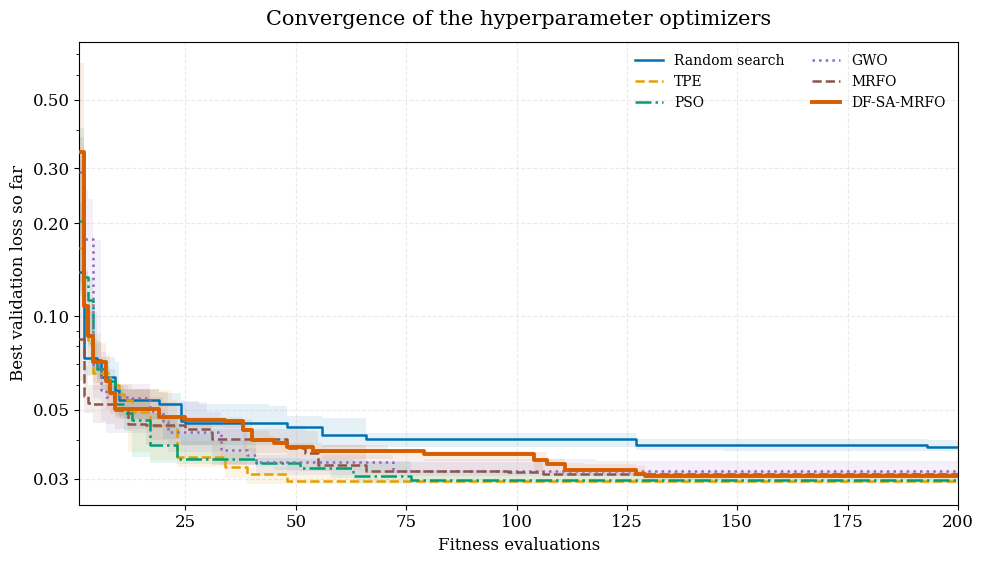

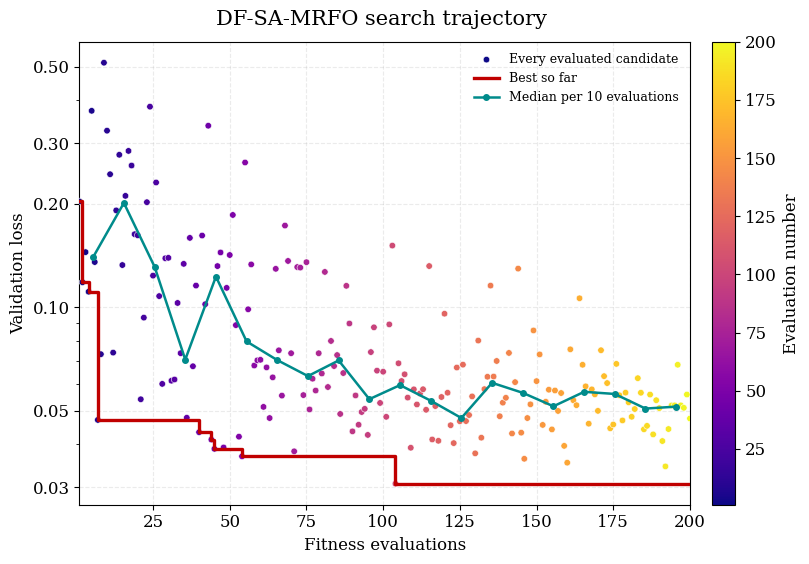

In [ ]:

from scipy import stats
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Redefine SEARCH_SPACE locally to ensure the cell is resilient to prior interrupts
SEARCH_SPACE = [
    ("lr",         1e-4, 2e-3, "log"),
    ("emb_dim",    16,   128,  "int"),
    ("n_blocks",   2,    6,    "int"),
    ("n_heads",    2,    8,    "int"),
    ("fm_hidden",  64,   512,  "int"),
    ("dropout",    0.10, 0.50, "float"),
    ("batch_size", 64,   256,  "int"),
    ("l2",         1e-6, 1e-2, "log"),
]
DIM = len(SEARCH_SPACE)

def decode(pos):
    hp = {}
    for v, (name, lo, hi, kind) in zip(np.clip(pos, 0, 1), SEARCH_SPACE):
        if kind == "log":   hp[name] = float(10 ** (np.log10(lo) + v * (np.log10(hi) - np.log10(lo))))
        elif kind == "int": hp[name] = int(round(lo + v * (hi - lo)))
        else:               hp[name] = float(lo + v * (hi - lo))
    hp["emb_dim"] = min([16, 32, 64, 128], key=lambda e: (abs(e - hp["emb_dim"]), e))
    h = hp["n_heads"]
    hp["n_heads"] = min([x for x in range(2, 9) if hp["emb_dim"] % x == 0], key=lambda x: (abs(x - h), x))
    hp["fm_hidden"]  = int(64 * round(hp["fm_hidden"] / 64))
    hp["batch_size"] = int(32 * round(hp["batch_size"] / 32))
    hp["lr"]      = round(hp["lr"], 4)
    hp["dropout"] = round(round(hp["dropout"] / 0.05) * 0.05, 2)
    hp["l2"]      = float(f"{hp['l2']:.0e}")
    return hp

def encode(hp):
    pos = []
    for name, lo, hi, kind in SEARCH_SPACE:
        v = hp[name]
        pos.append((np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)) if kind == "log" else (v - lo) / (hi - lo))
    return np.clip(np.array(pos), 0, 1)

STUDY = "quick"
OPT_BUDGET, OPT_SEEDS = (200, [1, 2, 3, 4, 5, 6]) if STUDY == "manuscript" else (30, [1, 2, 3])
FID_FRAC, FID_EPOCHS = 0.30, 10
OPT_NAMES = ["Random search", "TPE", "PSO", "GWO", "Standard MRFO", "DF-SA-MRFO"]
try:
    import optuna
except ImportError:
    print("[TPE skipped — run:  !pip install optuna]"); OPT_NAMES.remove("TPE")


_i30, _ = train_test_split(np.arange(len(y_train)), train_size=FID_FRAC, stratify=y_train, random_state=SEED)
STUDY_DATA = ((Xc_tr[_i30], Xk_tr[_i30], y_train[_i30]), (Xc_va, Xk_va, y_val))
FULL_DATA = ((Xc_tr, Xk_tr, y_train), (Xc_va, Xk_va, y_val))
_cache = {}
def study_fitness(pos, seed):
    hp = decode(pos); key = json.dumps(hp, sort_keys=True) + f"|{seed}"
    if key not in _cache: _cache[key] = train_model_ext(hp, STUDY_DATA, FID_EPOCHS, seed=seed)[2]
    return _cache[key]

class BudgetExhausted(Exception): pass
class Budgeted:
    """Counts EVERY fitness call (initial population and re-evaluations included); stops the optimizer at the budget."""
    def __init__(self, fn, budget):
        self.fn, self.budget, self.n = fn, budget, 0
        self.best, self.best_pos, self.trace, self.vals = np.inf, None, [], []
    def __call__(self, pos):
        if self.n >= self.budget: raise BudgetExhausted
        pos = np.clip(np.asarray(pos, float), 0, 1); v = float(self.fn(pos)); self.n += 1
        self.vals.append(v)
        if v < self.best: self.best, self.best_pos = v, pos.copy()
        self.trace.append(self.best)
        return v
def run_random(bf, rng, seed):
    while True: bf(rng.random(DIM))

def run_tpe(bf, rng, seed):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(lambda t: bf(np.array([t.suggest_float(f"x{i}", 0, 1) for i in range(DIM)])), n_trials=bf.budget)

def run_pso(bf, rng, seed, Q=OPT_POP, w=0.7, c1=1.5, c2=1.5):
    x = rng.random((Q, DIM)); v = np.zeros_like(x); pb = x.copy(); pf = np.array([bf(p) for p in x])
    while True:                                                           # ~19 iterations for a budget of 200
        gb = pb[pf.argmin()].copy()
        for q in range(Q):
            v[q] = w * v[q] + c1 * rng.random(DIM) * (pb[q] - x[q]) + c2 * rng.random(DIM) * (gb - x[q])
            x[q] = np.clip(x[q] + v[q], 0, 1); f = bf(x[q])
            if f < pf[q]: pf[q], pb[q] = f, x[q].copy()

def run_gwo(bf, rng, seed, Q=OPT_POP):
    T = max(1, bf.budget // Q); x = rng.random((Q, DIM)); f = np.array([bf(p) for p in x]); it = 0
    while True:                                                           # ~19 iterations for a budget of 200
        lead = [x[i].copy() for i in np.argsort(f)[:3]]; a = 2 * (1 - min(it, T) / T)
        for q in range(Q):
            new = np.zeros(DIM)
            for L in lead:
                A = 2 * a * rng.random(DIM) - a; C = 2 * rng.random(DIM); new += L - A * np.abs(C * L - x[q])
            x[q] = np.clip(new / 3, 0, 1); f[q] = bf(x[q])
        it += 1

def run_mrfo(bf, rng, seed, Q=OPT_POP, S=2.0, eps=1e-12):
    """Standard MRFO — same update rules as the mrfo() cell of this notebook, under an evaluation budget."""
    T = max(1, bf.budget // (2 * Q)); X = rng.random((Q, DIM)); fit = np.array([bf(p) for p in X])
    b = int(np.argmin(fit)); best_pos, best_fit = X[b].copy(), fit[b]; t = 0
    while True:
        t += 1; tt = min(t, T)
        for i in range(Q):
            ahead = best_pos if i == 0 else X[i - 1]
            if rng.random() < 0.5:                                        # cyclone foraging
                r1 = rng.random(); beta = 2 * np.exp(r1 * (T - tt + 1) / T) * np.sin(2 * np.pi * r1)
                ref = rng.random(DIM) if tt / T < rng.random() else best_pos
                trial = ref + rng.random(DIM) * (ahead - X[i]) + beta * (ref - X[i])
            else:                                                         # chain foraging
                alpha = 2 * rng.random(DIM) * np.sqrt(np.abs(np.log(rng.random(DIM) + eps)))
                trial = X[i] + rng.random(DIM) * (ahead - X[i]) + alpha * (best_pos - X[i])
            trial = np.clip(trial, 0, 1); ft = bf(trial)
            if ft < fit[i]: X[i], fit[i] = trial, ft
            if ft < best_fit: best_pos, best_fit = trial.copy(), ft
        for i in range(Q):
            trial = np.clip(X[i] + S * (rng.random() * best_pos - rng.random() * X[i]), 0, 1); ft = bf(trial)
            if ft < fit[i]: X[i], fit[i] = trial, ft
            if ft < best_fit: best_pos, best_fit = trial.copy(), ft

def run_dfsamrfo(bf, rng, seed, Q=OPT_POP, omega_min=0.5, omega_max=2.0, rho=0.20, alpha0=1.0, beta0=0.50,
                 xi0=0.10, tau_s=1e-4, stall_iters=5, disp_scale=0.05, eps=1e-12):
    """DF-SA-MRFO — same update rules as df_sa_mrfo() of this notebook, under an evaluation budget."""
    T = max(1, bf.budget // (2 * Q)); theta = rng.random((Q, DIM)); fit = np.array([bf(p) for p in theta])
    b = int(np.argmin(fit)); best_pos, best_fit = theta[b].copy(), fit[b]
    D0 = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1)); beta, stall, t = beta0, 0, 0
    while True:
        t += 1; tt = min(t, T); prev_best = best_fit
        delta = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1)) / (D0 + eps)
        omega = float(np.clip(1 - delta, omega_min, omega_max))
        alpha = alpha0 * (1 - tt / T) + omega * tt / T; p_explore = alpha / (alpha + beta)
        s = np.zeros(Q); disp = np.zeros_like(theta)
        for q in range(Q):
            if rng.random() < p_explore:
                r = rng.choice([i for i in range(Q) if i != q]); trial = theta[q] + alpha * rng.random(DIM) * (theta[r] - theta[q])
            else:
                trial = theta[q] + beta * rng.random(DIM) * (best_pos - theta[q])
            trial = np.clip(trial, 0, 1); ft = bf(trial)
            if ft < fit[q]: s[q] = 1; disp[q] = trial - theta[q]; theta[q], fit[q] = trial, ft
        SR = s.mean(); gamma = beta * SR; beta = (1 - rho) * beta + rho * SR
        mean_dir = disp.sum(0) / (s.sum() + eps) if s.sum() > 0 else np.zeros(DIM)
        for q in range(Q):
            new = np.clip(theta[q] + gamma * mean_dir + omega * rng.normal(0, disp_scale, DIM), 0, 1); fn_ = bf(new)
            theta[q], fit[q] = new, fn_
            if fn_ < best_fit: best_pos, best_fit = new.copy(), fn_
        b = int(np.argmin(fit))
        if fit[b] < best_fit: best_pos, best_fit = theta[b].copy(), fit[b]
        stall = stall + 1 if abs(prev_best - best_fit) < tau_s else 0
        if stall >= stall_iters:
            xi = xi0 * (1 - tt / T)
            for q in np.argsort(fit)[-(Q // 2):]:
                theta[q] = np.clip(best_pos + xi * rng.uniform(-1, 1, DIM), 0, 1); fit[q] = bf(theta[q])
                if fit[q] < best_fit: best_pos, best_fit = theta[q].copy(), fit[q]
            stall = 0

RUNNERS = {"Random search": run_random, "TPE": run_tpe, "PSO": run_pso, "GWO": run_gwo,
           "Standard MRFO": run_mrfo, "DF-SA-MRFO": run_dfsamrfo}

STATE_PATH = os.path.join(OUT_DIR, f"optimizer_study_{STUDY}.json")
STATE = json.load(open(STATE_PATH)) if os.path.exists(STATE_PATH) else {}
for seed in OPT_SEEDS:
    for name in OPT_NAMES:
        key = f"{name}|{seed}"
        if key in STATE: continue
        t0 = time.time(); rng = np.random.default_rng(seed)
        bf = Budgeted(lambda pos, s=seed: study_fitness(pos, s), OPT_BUDGET)
        try: RUNNERS[name](bf, rng, seed)
        except BudgetExhausted: pass
        hp = decode(bf.best_pos)
        model, _, _ = train_model_ext(hp, FULL_DATA, FINAL_EPOCHS, seed=seed)
        p = predict_proba(model, Xc_te, Xk_te, hp["batch_size"])
        acc = float(((p >= TAU).astype(int) == y_test).mean() * 100)
        STATE[key] = {"acc": acc, "hp": hp, "best_loss": bf.best, "trace": bf.trace, "vals": bf.vals}
        json.dump(STATE, open(STATE_PATH, "w"))
        print(f"seed {seed} | {name:14s} | {bf.n} evals | best reduced-fidelity val loss {bf.best:.4f} | test accuracy {acc:.2f}% | {(time.time()-t0)/60:.1f} min")

done = [s for s in OPT_SEEDS if all(f"{n}|{s}" in STATE for n in OPT_NAMES)]
acc = pd.DataFrame({n: [STATE[f"{n}|{s}"]["acc"] for s in done] for n in OPT_NAMES}, index=done)
ranks = acc.rank(axis=1, ascending=False)                      # rank 1 = highest accuracy in that seed
ms = lambda v: f"{np.mean(v):.2f} ± {np.std(v, ddof=1):.2f}"

table = pd.DataFrame({"Seed": [str(s) for s in done] + ["Mean ± SD", "Mean rank"]})
for n in OPT_NAMES:
    table[n] = [f"{a:.2f}" for a in acc[n]] + [ms(acc[n]), f"{ranks[n].mean():.2f}"]
print(table.to_string(index=False))
table.to_csv(os.path.join(OUT_DIR, f"optimizer_comparison_{STUDY}.csv"), index=False)

# convergence of all optimizers
xs = np.arange(1, OPT_BUDGET + 1)
plt.figure(figsize=(9, 6))
for n in OPT_NAMES:
    M = np.vstack([np.pad(STATE[f"{n}|{s}"]["trace"], (0, max(0, OPT_BUDGET - len(STATE[f"{n}|{s}"]["trace"]))),
                          mode="edge")[:OPT_BUDGET] for s in done])
    ln, = plt.plot(xs, np.median(M, 0), lw=2, label=n, drawstyle="steps-post")
    plt.fill_between(xs, np.percentile(M, 25, 0), np.percentile(M, 75, 0), alpha=0.12, color=ln.get_color(), step="post")
plt.xlabel("Fitness evaluations", fontsize=13); plt.ylabel("Best-so-far validation loss", fontsize=13)
plt.title("Convergence of the hyperparameter optimizers", fontsize=15, pad=12)
plt.legend(fontsize=11, frameon=True); plt.grid(True, linestyle="--", alpha=0.3)
save_fig(f"convergence_all_optimizers_{STUDY}.png")

#  all candidates of the median DF-SA-MRFO run
fin = {s: STATE[f"DF-SA-MRFO|{s}"]["best_loss"] for s in done}
s_med = sorted(fin, key=fin.get)[len(fin) // 2]                # run with the median final loss
v = np.array(STATE[f"DF-SA-MRFO|{s_med}"]["vals"]); k = np.arange(1, len(v) + 1)
blocks = [(i, v[i:i + 10]) for i in range(0, len(v), 10)]
plt.figure(figsize=(9, 6))
plt.scatter(k, v, s=18, color="#9ecae1", label="Evaluated candidates")
plt.plot(k, np.minimum.accumulate(v), color="#D62728", lw=2.2, drawstyle="steps-post", label="Best so far")
plt.plot([i + 5.5 for i, b in blocks], [np.median(b) for _, b in blocks], color="#08519c", lw=1.8,
         marker="o", ms=4, label="Median loss per 10 evaluations")
plt.xlabel("Fitness evaluations", fontsize=13); plt.ylabel("Validation loss (reduced fidelity)", fontsize=13)
plt.title(f"DF-SA-MRFO search trajectory", fontsize=15, pad=12)
plt.legend(fontsize=11, frameon=True); plt.grid(True, linestyle="--", alpha=0.3)
save_fig(f"dfsamrfo_trajectory_{STUDY}.png")
plt.show()

In [ ]:

OMEGA_CONST = 1.0

def run_dfsamrfo_abl(bf, rng, seed, use_df=True, use_sa=True, use_reloc=True, Q=OPT_POP,
                     omega_min=0.5, omega_max=2.0, rho=0.20, alpha0=1.0, beta0=0.50,
                     xi0=0.10, tau_s=1e-4, stall_iters=5, disp_scale=0.05, eps=1e-12):
    T = max(1, bf.budget // (2 * Q)); theta = rng.random((Q, DIM)); fit = np.array([bf(p) for p in theta])
    b = int(np.argmin(fit)); best_pos, best_fit = theta[b].copy(), fit[b]
    D0 = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1)); beta, stall, t = beta0, 0, 0
    while True:
        t += 1; tt = min(t, T); prev_best = best_fit
        if use_df:
            delta = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1)) / (D0 + eps)
            omega = float(np.clip(1 - delta, omega_min, omega_max))
        else:
            omega = OMEGA_CONST
        alpha = alpha0 * (1 - tt / T) + omega * tt / T; p_explore = alpha / (alpha + beta)
        s = np.zeros(Q); disp = np.zeros_like(theta)
        for q in range(Q):
            if rng.random() < p_explore:
                r = rng.choice([i for i in range(Q) if i != q]); trial = theta[q] + alpha * rng.random(DIM) * (theta[r] - theta[q])
            else:
                trial = theta[q] + beta * rng.random(DIM) * (best_pos - theta[q])
            trial = np.clip(trial, 0, 1); ft = bf(trial)
            if ft < fit[q]: s[q] = 1; disp[q] = trial - theta[q]; theta[q], fit[q] = trial, ft
        SR = s.mean()
        if use_sa:
            gamma = beta * SR; beta = (1 - rho) * beta + rho * SR
            mean_dir = disp.sum(0) / (s.sum() + eps) if s.sum() > 0 else np.zeros(DIM)
        else:
            gamma = 0.0; beta = beta0; mean_dir = np.zeros(DIM)
        for q in range(Q):
            new = np.clip(theta[q] + gamma * mean_dir + omega * rng.normal(0, disp_scale, DIM), 0, 1); fn_ = bf(new)
            theta[q], fit[q] = new, fn_
            if fn_ < best_fit: best_pos, best_fit = new.copy(), fn_
        b = int(np.argmin(fit))
        if fit[b] < best_fit: best_pos, best_fit = theta[b].copy(), fit[b]
        stall = stall + 1 if abs(prev_best - best_fit) < tau_s else 0
        if use_reloc and stall >= stall_iters:
            xi = xi0 * (1 - tt / T)
            for q in np.argsort(fit)[-(Q // 2):]:
                theta[q] = np.clip(best_pos + xi * rng.uniform(-1, 1, DIM), 0, 1); fit[q] = bf(theta[q])
                if fit[q] < best_fit: best_pos, best_fit = theta[q].copy(), fit[q]
            stall = 0

ABL_RUNNERS = {
    "Without diversity feedback":           lambda bf, rng, seed: run_dfsamrfo_abl(bf, rng, seed, use_df=False),
    "Without success-adaptive following":   lambda bf, rng, seed: run_dfsamrfo_abl(bf, rng, seed, use_sa=False),
    "Without stagnation-aware relocation":  lambda bf, rng, seed: run_dfsamrfo_abl(bf, rng, seed, use_reloc=False),
}

#  run the three ablated variants
for seed in OPT_SEEDS:
    for name, runner in ABL_RUNNERS.items():
        key = f"{name}|{seed}"
        if key in STATE: continue
        t0 = time.time(); rng = np.random.default_rng(seed)
        bf = Budgeted(lambda pos, s=seed: study_fitness(pos, s), OPT_BUDGET)
        try: runner(bf, rng, seed)
        except BudgetExhausted: pass
        hp = decode(bf.best_pos)
        model, _, _ = train_model_ext(hp, FULL_DATA, FINAL_EPOCHS, seed=seed)
        p = predict_proba(model, Xc_te, Xk_te, hp["batch_size"])
        acc_ = float(((p >= TAU).astype(int) == y_test).mean() * 100)
        STATE[key] = {"acc": acc_, "hp": hp, "best_loss": bf.best, "trace": bf.trace, "vals": bf.vals}
        json.dump(STATE, open(STATE_PATH, "w"))
        print(f"seed {seed} | {name:36s} | {bf.n} evals | best val loss {bf.best:.4f} | test accuracy {acc_:.2f}% | {(time.time()-t0)/60:.1f} min")

ABL_ROWS = [("Full DF-SA-MRFO", "DF-SA-MRFO"),
            ("Without diversity feedback", "Without diversity feedback"),
            ("Without success-adaptive following", "Without success-adaptive following"),
            ("Without stagnation-aware relocation", "Without stagnation-aware relocation"),
            ("All disabled (standard MRFO)", "Standard MRFO")]
done = [s for s in OPT_SEEDS if all(f"{k}|{s}" in STATE for _, k in ABL_ROWS)]
A = {lab: np.array([STATE[f"{k}|{s}"]["acc"] for s in done]) for lab, k in ABL_ROWS}
full = A["Full DF-SA-MRFO"]

def wilcoxon_p(a, b):
    d = np.asarray(a) - np.asarray(b)
    if np.allclose(d, 0): return 1.0
    return float(stats.wilcoxon(a, b, alternative="two-sided").pvalue)

abl_labels = [lab for lab, _ in ABL_ROWS[1:]]
p_raw = [wilcoxon_p(full, A[lab]) for lab in abl_labels]
p_holm = holm(p_raw)

rows = [{"Variant": "Full DF-SA-MRFO", "Test accuracy (%), mean ± SD": mean_sd(full),
           "Δ vs. full": "–", "Wilcoxon p": "–", "Holm-adjusted p": "–"}]
for lab, pr, ph in zip(abl_labels, p_raw, p_holm):
    rows.append({"Variant": lab, "Test accuracy (%), mean ± SD": mean_sd(A[lab]),
                   "Δ vs. full": f"{np.mean(A[lab]) - np.mean(full):+.2f}".replace("-", "−"),
                   "Wilcoxon p": f"{pr:.3f}", "Holm-adjusted p": f"{ph:.3f}"})
table = pd.DataFrame(rows)
print(f"\nAblation of the DF-SA-MRFO mechanisms\n")
show(table, f"dfsamrfo_ablation_{STUDY}")

Ablation of the DF-SA-MRFO mechanisms 
                                         Variant   Test accuracy (%), mean ± SD   Δ vs. full   Wilcoxon p   Holm-adjusted p
                                 Full DF-SA-MRFO                   98.65 ± 0.14            –            –                 –
                      Without diversity feedback                   98.57 ± 0.12        −0.08        0.312             0.656
              Without success-adaptive following                   98.54 ± 0.10        −0.10        0.156             0.625
             Without stagnation-aware relocation                   98.64 ± 0.12        −0.01        0.844             0.844
                    All disabled (standard MRFO)                   98.52 ± 0.16        −0.13        0.219             0.656


In [1]:
M = pd.DataFrame({n: [STATE[f"{n}|{s}"]["acc"] for s in OPT_SEEDS] for n in OPT_NAMES}, index=OPT_SEEDS)
chi2, p = stats.friedmanchisquare(*[M[n] for n in OPT_NAMES])
print(f"Friedman chi2 = {chi2:.2f}, p = {p:.3f}")
others = [n for n in OPT_NAMES if n != "DF-SA-MRFO"]
raw = [wilcoxon_p(M["DF-SA-MRFO"], M[n]) for n in others]
adj = holm(raw)
for n, r, a in zip(others, raw, adj):
    print(f"DF-SA-MRFO vs {n:14s}: wins {(M['DF-SA-MRFO'] > M[n]).sum()}/{len(OPT_SEEDS)} | raw p {r:.3f} | Holm p {a:.3f}")

Friedman chi2 = 13.81, p = 0.017
DF-SA-MRFO vs Random search : wins 5/6 | raw p 0.062 | Holm p 0.250
DF-SA-MRFO vs TPE           : wins 5/6 | raw p 0.062 | Holm p 0.250
DF-SA-MRFO vs PSO           : wins 5/6 | raw p 0.094 | Holm p 0.250
DF-SA-MRFO vs GWO           : wins 6/6 | raw p 0.031 | Holm p 0.156
DF-SA-MRFO vs Standard MRFO : wins 4/6 | raw p 0.219 | Holm p 0.250
